# Does analog matching work?

**Question.** Are launch curves in the same class (ATC 4, ATC 3), area, route, volume band or launch cohort more alike than random pairs? Does the median curve of an analog's group predict its own first 3 years (Q0–Q12) when it's held out?

**Why.** The tool's step 2 picks analogs by similarity on structured features, then borrows their uptake shape. If same-group curves aren't closer than random ones, that feature shouldn't carry weight in the similarity score. `volume_vs_shape` found small and large Medicaid drugs have different shapes, so volume is tested alongside class.

Reads `data/processed/` only. Uses the area definition shared across the EDAs (ATC 1, L split into oncology and immunology) and `volume_vs_shape`'s volume bands.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# run from the repo root or from eda/
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))  # for pipeline.common / pipeline.bass

# same chart style and categorical order as the other EDA notebooks (blue, orange, aqua; validated for CVD)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8f8e89"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 9,
})
pd.set_option("display.width", 200)

In [2]:
from pipeline.common import qnum

features = pd.read_csv(PROCESSED / "analog_features.csv")
analogs = pd.read_csv(PROCESSED / "analogs.csv", dtype=str, keep_default_na=False)
curves = pd.read_csv(PROCESSED / "launch_curves.csv")
history = pd.read_csv(PROCESSED / "indication_history.csv")
sdud = pd.read_csv(PROCESSED / "sdud_quarterly.csv")
trx = sdud[sdud.metric == "trx"].assign(value=lambda d: pd.to_numeric(d.value, errors="coerce"))

# usable = end of the checks.md funnel
usable = set(features.loc[features.enough_data & ~features.late_launch & ~features.generic_entry_in_window, "analog_id"])

# same area definition as launch_eda, volume_vs_shape and pool_funnel: ATC 1, L split into oncology and immunology
# (classes are each analog's own since the pipeline's ATC fix, so Jakafi and Daliresp aren't "Dermatology")
ATC1 = {"A": "Alimentary & metabolism", "B": "Blood", "C": "Cardiovascular", "D": "Dermatology",
        "G": "GU & sex hormones", "H": "Systemic hormones", "J": "Anti-infectives", "M": "Musculoskeletal",
        "N": "Nervous system", "P": "Antiparasitic", "R": "Respiratory", "S": "Sensory organs", "V": "Various"}
broad = features.class_broad.fillna("")
features["area"] = broad.str[:1].map(ATC1).fillna("No ATC class")
features.loc[broad.str.startswith(("L01", "L02")), "area"] = "Oncology"
features.loc[broad.str.startswith(("L03", "L04")), "area"] = "Immunology"
print(f"{len(features)} analogs, {len(usable)} usable")

426 analogs, 250 usable


## 1. Curve distance

Each usable analog's share of peak (current definition: ÷ the Q0–Q20 peak) over Q0–Q12, non-provisional quarters. Distance between two analogs = mean absolute gap in share of peak over the quarters both have, so 0.10 means the curves sit 10 points of peak apart on average.

In [3]:
u = features[features.analog_id.isin(usable)].copy()
u["atc4"] = u.class_narrow.str.split("; ").str[0].str[:5]
u["atc3"] = u.class_broad.str.split("; ").str[0].str[:4]
u["volume_band"] = pd.cut(u.peak_trx, [0, 766, 14748, np.inf], labels=["small", "mid", "large"])  # as in volume_vs_shape
year = u.analog_id.map(analogs.set_index("analog_id")["approval date"]).str[:4].astype(int)
u["cohort"] = pd.cut(year, [2009, 2013, 2017, 2021, 2025], labels=["2010-13", "2014-17", "2018-21", "2022-25"])
u["area_x_volume"] = u.area + " | " + u.volume_band.astype(str)
u["atc3_x_volume"] = u.atc3 + " | " + u.volume_band.astype(str)
u = u.set_index("analog_id")
ids = u.index.tolist()

first3 = curves[curves.analog_id.isin(usable) & ~curves.provisional & (curves.q_since_launch <= 12)]

def curve_matrix(values):
    return first3.pivot(index="analog_id", columns="q_since_launch", values=values).reindex(ids).to_numpy(float)

def distances(X):
    return np.array([np.nanmean(np.abs(X - X[i]), axis=1) for i in range(len(X))])

X = curve_matrix("share_of_peak")
D = distances(X)
iu = np.triu_indices(len(ids), 1)
pairs = D[iu]
print(f"{len(ids)} usable analogs, {len(pairs):,} pairs; distance quartiles "
      f"{np.quantile(pairs, .25):.3f} / {np.median(pairs):.3f} / {np.quantile(pairs, .75):.3f}")

250 usable analogs, 31,125 pairs; distance quartiles 0.131 / 0.220 / 0.335


## 2. Same group vs random pairs

Mean distance of pairs in the same group, divided by the mean over all pairs where both have the feature (< 1 = more alike). p-value: share of 1,000 label shuffles (among analogs that have the feature) that give a same-group mean at least as low.

In [4]:
GROUPS = {"ATC 4 class": "atc4", "ATC 3 class": "atc3", "area": "area", "route": "route_group",
          "volume band": "volume_band", "launch cohort": "cohort"}
rng = np.random.default_rng(2026)

def same_group_test(col, n_perm=1000):
    lab = u[col].astype(object).to_numpy()
    known = pd.notna(lab)
    valid = (known[:, None] & known[None, :])[iu]
    def mean_same(lbl):
        return pairs[(lbl[:, None] == lbl[None, :])[iu] & valid].mean()
    observed = mean_same(lab)
    shuffled = []
    for _ in range(n_perm):
        perm = lab.copy()
        perm[known] = rng.permutation(lab[known])
        shuffled.append(mean_same(perm))
    same_pairs = int(((lab[:, None] == lab[None, :])[iu] & valid).sum())
    return {"same-group pairs": same_pairs, "same-group distance": observed, "all-pairs distance": pairs[valid].mean(),
            "ratio": observed / pairs[valid].mean(), "p": (np.sum(np.array(shuffled) <= observed) + 1) / (n_perm + 1)}

pair_test = pd.DataFrame({label: same_group_test(col) for label, col in GROUPS.items()}).T
pair_test["same-group pairs"] = pair_test["same-group pairs"].astype(int)
pair_test.sort_values("ratio").round(3)

,same-group pairs,same-group distance,all-pairs distance,ratio,p
ATC 4 class,292,0.222,0.246,0.901,0.009
volume band,11125,0.231,0.244,0.947,0.001
launch cohort,9912,0.240,0.244,0.984,0.054
ATC 3 class,1645,0.244,0.246,0.993,0.458
area,4079,0.244,0.244,1.002,0.536
route,21429,0.246,0.244,1.010,0.793


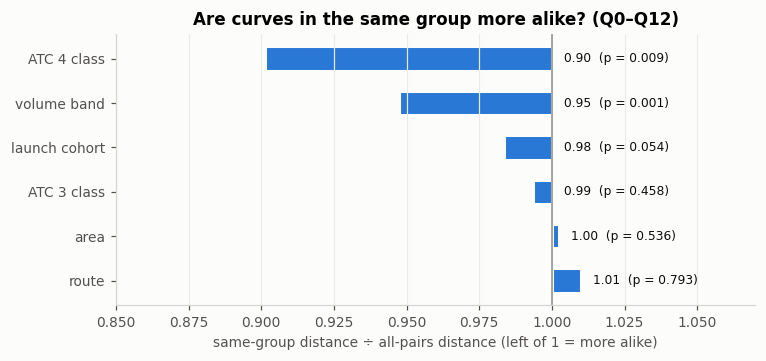

In [5]:
t_ = pair_test.sort_values("ratio", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(t_.index, t_.ratio - 1, left=1, color=BLUE, height=0.55, edgecolor="#fcfcfb", linewidth=2)
for i, (r, p) in enumerate(zip(t_.ratio, t_.p)):
    ax.text(max(r, 1) + 0.004, i, f"{r:.2f}  (p = {p:.3f})", va="center", fontsize=8, color=INK)
ax.axvline(1, color=GRAY, lw=1)
ax.set_xlim(0.85, 1.07)
ax.set_xlabel("same-group distance ÷ all-pairs distance (left of 1 = more alike)")
ax.set_title("Are curves in the same group more alike? (Q0–Q12)")
ax.grid(axis="y", visible=False)
plt.show()

## 3. Holdout preview

Leave one usable analog out and predict its Q0–Q12 curve with the median curve of the other analogs in its group; error = mean absolute gap in share of peak. Groups need at least 3 other members. Each grouping is compared with the overall median (all other analogs) on the same analogs, so the comparison is paired. Run twice: share of the Q0–Q20 peak (current), and share of each analog's own Q0–Q12 peak (shape inside the forecast window only, independent of the peak question in `peak_window`).

In [6]:
HOLDOUT = {**GROUPS, "area × volume": "area_x_volume", "ATC 3 × volume": "atc3_x_volume"}

def holdout(X):
    labels = {name: u[col].astype(object).to_numpy() for name, col in HOLDOUT.items()}
    rows = []
    for i in range(len(ids)):
        others = np.arange(len(ids)) != i
        row = {"analog_id": ids[i], "all analogs": np.nanmean(np.abs(X[i] - np.nanmedian(X[others], axis=0)))}
        for name, lab in labels.items():
            members = others & (lab == lab[i]) if pd.notna(lab[i]) and "nan" not in str(lab[i]) else np.zeros(len(ids), bool)
            row[name] = np.nanmean(np.abs(X[i] - np.nanmedian(X[members], axis=0))) if members.sum() >= 3 else np.nan
        rows.append(row)
    err = pd.DataFrame(rows).set_index("analog_id")
    out = {}
    for name in HOLDOUT:
        m = err[name].notna()
        gain = err.loc[m, "all analogs"] - err.loc[m, name]
        out[name] = {"analogs": int(m.sum()), "error, overall median": round(err.loc[m, "all analogs"].median(), 3),
                     "error, group median": round(err.loc[m, name].median(), 3),
                     "improvement %": round(100 * gain.median() / err.loc[m, "all analogs"].median()),
                     "% of analogs better": round(100 * (gain > 0).mean())}
    return err, pd.DataFrame(out).T.astype({"analogs": int, "improvement %": int, "% of analogs better": int})

# share of each analog's own Q0-Q12 peak
own12 = first3.assign(v=first3.trx / first3.groupby("analog_id").trx.transform("max"))
X12 = own12.pivot(index="analog_id", columns="q_since_launch", values="v").reindex(ids).to_numpy(float)

err_q20, res_q20 = holdout(X)
err_q12, res_q12 = holdout(X12)
pd.concat({"share of Q0–Q20 peak": res_q20, "share of own Q0–Q12 peak": res_q12}, axis=1)

/var/folders/rv/20khs4wj23b5gsv2k6jf_23h0000gn/T/ipykernel_37932/2901673626.py:11: RuntimeWarning: All-NaN slice encountered
  row[name] = np.nanmean(np.abs(X[i] - np.nanmedian(X[members], axis=0))) if members.sum() >= 3 else np.nan


/var/folders/rv/20khs4wj23b5gsv2k6jf_23h0000gn/T/ipykernel_37932/2901673626.py:11: RuntimeWarning: All-NaN slice encountered
  row[name] = np.nanmean(np.abs(X[i] - np.nanmedian(X[members], axis=0))) if members.sum() >= 3 else np.nan


share of Q0–Q20 peak                                                                             share of own Q0–Q12 peak                                                          \
                            analogs error, overall median error, group median improvement % % of analogs better                  analogs error, overall median error, group median improvement %   
ATC 4 class                      95                 0.159               0.172            -7                  45                       95                 0.142               0.145            -6   
ATC 3 class                     187                 0.148               0.170            -7                  45                      187                 0.121               0.127            -5   
area                            243                 0.146               0.159            -4                  38                      243                 0.115               0.122            -1   
route                           250                 0.147               0.141             2                  52                      250                 0.115               0.115             4   
volume band                     250                 0.147               0.139            14                  60                      250                 0.115               0.116             8   
launch cohort                   250                 0.147               0.147             2                  52                      250                 0.115               0.121            -1   
area × volume                   227                 0.146               0.148             2                  51                      227                 0.115               0.128            -3   
ATC 3 × volume                  143                 0.146               0.149             8                  57                      143                 0.120               0.131             6   

                                    
               % of analogs better  
ATC 4 class                     46  
ATC 3 class                     44  
area                            48  
route                           56  
volume band                     55  
launch cohort                   46  
area × volume                   48  
ATC 3 × volume                  54

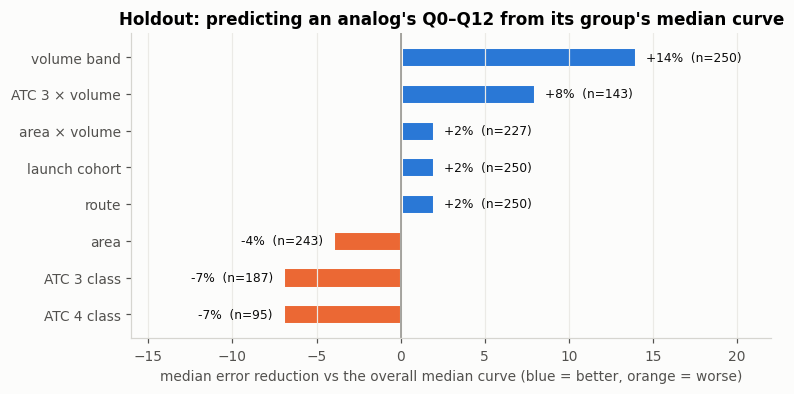

In [7]:
r_ = res_q20.sort_values("improvement %")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
colors = [BLUE if v > 0 else ORANGE for v in r_["improvement %"]]
ax.barh(r_.index, r_["improvement %"], color=colors, height=0.55, edgecolor="#fcfcfb", linewidth=2)
for i, (v, n) in enumerate(zip(r_["improvement %"], r_.analogs)):
    ax.text(v + (0.6 if v >= 0 else -0.6), i, f"{v:+.0f}%  (n={n})", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=INK)
ax.axvline(0, color=GRAY, lw=1)
ax.set_xlim(-16, 22)
ax.set_xlabel("median error reduction vs the overall median curve (blue = better, orange = worse)")
ax.set_title("Holdout: predicting an analog's Q0–Q12 from its group's median curve")
ax.grid(axis="y", visible=False)
plt.show()

## 4. What it means for the similarity score

Does the pattern hold inside the larger areas? Median error reduction from ATC 4 class and from volume band, within each area (share of the Q0–Q20 peak).

In [8]:
within = []
for area_name, d in u.groupby("area"):
    if len(d) < 25:
        continue
    e = err_q20.loc[d.index]
    for name in ["ATC 4 class", "volume band"]:
        m = e[name].notna()
        if m.sum() >= 5:
            gain = e.loc[m, "all analogs"] - e.loc[m, name]
            within.append({"area": area_name, "grouping": name, "analogs": int(m.sum()),
                           "improvement %": round(100 * gain.median() / e.loc[m, "all analogs"].median())})
pd.DataFrame(within).pivot(index="area", columns="grouping", values=["improvement %", "analogs"])

improvement %                 analogs            
grouping                  ATC 4 class volume band ATC 4 class volume band
area                                                                     
Alimentary & metabolism             3          25           8          34
Immunology                          4          21          16          28
Nervous system                     -8           5          18          41
Oncology                          -10          22          28          62

## Takeaways

- **First-3-year shapes vary a lot, and mostly not by class.** Two usable analogs' Q0–Q12 curves sit 0.22 of peak apart on median (quartiles 0.13–0.34).
- **Pairs in the same ATC 4 class are somewhat more alike** (distance 0.90 of the average, p = 0.009), and so are pairs in the same Medicaid volume band (0.95, p = 0.001). Same ATC 3 class, area, route or launch cohort: no more alike than random pairs. (ATC classes corrected for 11 analogs whose first RxClass code came from a combination product or another route; see the load cell.)
- **But no group median predicts a held-out analog much better than the median of all analogs.** Against the overall median curve (error 0.15 of peak):
  - volume band is the only clear gain: 14% lower error, better for 60% of analogs. With curves normalized to their own Q0–Q12 peak it drops to 8% (55%), so part of the volume effect is small drugs plateauing before Q20 (`peak_window`), part is a real faster start (`volume_vs_shape`).
  - ATC 4 class makes predictions *worse* (−7%; −6% on own-Q12 shares). Most ATC 4 groups have 3–5 usable members, so their median is noisy, and only 95 analogs have ≥ 3 classmates. ATC 3 class (−7%) and area (−4%) are also worse.
  - Even a clean class doesn't help: the four SGLT2 inhibitors (Invokana, Farxiga, Jardiance, Steglatro) are predicted worse by their class median than by the overall median (error 0.125 vs 0.097). Same mechanism, different launches, plausibly because of order of entry.
  - Within areas, volume band helps in oncology (22%), immunology (21%) and alimentary & metabolism (25%), less in nervous system (5%).

**What it means for the tool.** The structured features in the similarity score (class, area, route) don't pick analogs whose first 3 years look like the held-out drug's, at least as group medians. Two consequences: the analog step should show the **spread** of the chosen analogs, not one borrowed curve, and the agent's re-rank (line of therapy, competition, dosing) has to carry the matching, which can only be tested once label reads are approved. Volume is the strongest structured signal, but a target drug's Medicaid volume isn't known before launch; the closest proxy is its expected patient population (the ceiling side).

**Open checks.** Nearest-neighbour matching on several features at once (instead of one group's median); the same test on Bass p, q rather than shares; the label-read features once approved.